# 演習6：H₄の同じ9点を、シミュレータと実機で測る

**R=2.0 Å・準備M=6・発展M=16・1回のGaussian更新**に固定します。
変更する実験パラメータは下の`SHOTS`だけです。認証情報・バックエンドは実機接続時に指定します。

| 固定する量 | 値                                                    |
| ---------- | ----------------------------------------------------- |
| 分子・構造 | 等間隔直鎖H₄、隣接距離R=2.0 Å、STO-3G、JW             |
| 回路       | 系8＋補助1 qubit、準備M=6、発展M=16                   |
| 読出し     | 全9ビットが0の回数 / 全shots                          |
| 事前       | Gaussian：中心0 Ha、分散4 Ha²（SD=2 Ha）              |
| 測定       | L=4、Δt=0.1、t=0.4、候補[-4,4] Haの9点                |
| 推定       | 測定曲線をGaussianフィットし、事前との積で1回だけ更新 |

以下の3通りを**独立したセル**で行います。すべて同じ近似回路・同じ事前・同じ9点を使い、前のセルの事後を引き継ぎません。

1. shot noiseなしシミュレーション
2. 有限shotsシミュレーション（ゲートノイズなし）
3. IBM実機測定（接続・プレビュー後、送信セルを明示的に有効化）

追加の第3a節では、`USE_FAKE_KAWASAKI=True` で過去のKawasakiスナップショットによるノイズ付き模擬測定を行えます。
この節はcountsの比較だけを行い、Gaussian更新はしません。Trueの間は後のIBM接続・実機送信をスキップします。

最初はシミュレーションだけで通し実行できます。実機接続・送信は既定で無効です。
初回の実機体験用であり、この深い回路で高精度なギャップが得られると保証する例ではありません。


In [ ]:
# 初回だけ必要に応じてコメントを外して実行し、カーネルを再起動してください。
# % pip install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "pylatexenc>=2.10,<3"
# 実機モードのみ追加: %pip install "qiskit-ibm-runtime>=0.43,<0.44"

  Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached scipy-1.18.1-cp312-cp312-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached rustworkx-0.18.1-cp310-abi3-macosx_11_0_arm64.whl.metadata (10 kB)
  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
  Using cached stevedore-5.9.1-py3-none-any.whl.metadata (2.3 kB)
  Using cached contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 7.7 MB/s eta 0:00:00 MB/s eta 0:00:01:01
Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl (5.5 MB)
Using cached scipy-1.18.1-cp312-cp312-macosx_14_0_arm64.whl (20.5 MB)
Using cached matplo

### データの取得先とキャッシュ

巨大な保存配列はNotebookへ埋め込みません。次セルは固定コミットから必要な回路・参照データを取得し、SHA-256を確認して再利用します。
リポジトリを取得済みなら、その中の固定データを優先します。なければローカルの `~/.cache/ftqc_handson/h4_pec_v1` へ保存します。
次セル先頭の `H4_CACHE_DIR` にパスを指定すると保存先を変えられます（環境変数 `H4_DATA_DIR` があればそちらが優先）。

Google Driveへ保存する場合は、先に別セルで次を実行し、その後 `H4_CACHE_DIR` を下記のパスに変更してください。

```python
from google.colab import drive
drive.mount('/content/drive')
# 次の初期化セルで指定:
# H4_CACHE_DIR = '/content/drive/MyDrive/FTQC_HandsOn/h4_pec_v1'
```

初回はネット接続が必要です。構造やMを変えたときは不足ファイルだけを取得し、既存ファイルは再ダウンロードしません。
オフラインで全選択肢を使う場合は、接続中に `download_h4_data()` で全20構造を事前取得します（約40 MiB）。
その後は `H4_OFFLINE=True` を選べます。補助コードも保存先の隣のruntimeフォルダへキャッシュします。
初期化セルは補助関数のため折り畳んであります。通常は先頭の設定だけを変更して実行してください。


In [1]:
H4_DATA_COMMIT = "4ab6ef3d06f4256b5c818feb8c3fa2af4381dd43"
# 保存先を指定する場合の例（Google Driveは先にmountする）:
# H4_CACHE_DIR = '/content/drive/MyDrive/FTQC_HandsOn/h4_pec_v1'
H4_CACHE_DIR = (
    None  # None: H4_DATA_DIR環境変数 → 取得済みリポジトリ → ユーザーキャッシュ
)
H4_OFFLINE = False  # True: ダウンロードせず、既存ファイルのみを使用

import os, json, hashlib, base64, tempfile
from pathlib import Path
from urllib.request import urlopen

SNAPSHOT_DIGEST = "6910f1f0aa7d0f2e43499683ba3a50f83db7aee09f3c64b07c91a6815ebdd4b3"
ASSET_DIGEST = SNAPSHOT_DIGEST
_H4_URL = f"https://raw.githubusercontent.com/QS-laboratory/IBM_handson/{H4_DATA_COMMIT}/hands_on/exercises/"
_H4_RUNTIME = {
    "h4_measurement.py": "d4dea4170f5e925599dcbbbc3b2c0ee7f2da1e25d7844ec024759e415c3a35f4",
    "h4_snapshot.py": "163691a0c005c844e0e449411c59eb5192218402df999c77056cbd7b223be997",
}


def snapshot_root():
    explicit = os.environ.get("H4_DATA_DIR") or H4_CACHE_DIR
    root = Path(explicit).expanduser().resolve() if explicit else None
    if root is None:
        for parent in [Path.cwd(), *Path.cwd().parents]:
            for candidate in [
                parent / "data/h4_pec_v1",
                parent / "hands_on/exercises/data/h4_pec_v1",
            ]:
                if (candidate / "manifest.json").is_file():
                    root = candidate
                    break
            if root is not None:
                break
    if root is None:
        root = Path.home() / ".cache/ftqc_handson/h4_pec_v1"
    if (
        str(root).startswith("/content/drive/MyDrive/")
        and not Path("/content/drive/MyDrive").is_dir()
    ):
        raise FileNotFoundError(
            '先に drive.mount("/content/drive") でGoogle Driveを接続してください'
        )
    manifest = root / "manifest.json"
    if (
        manifest.is_file()
        and hashlib.sha256(manifest.read_bytes()).hexdigest() != SNAPSHOT_DIGEST
    ):
        raise ValueError("Snapshot manifest differs from the pinned h4-pec-v1 manifest")
    return root


def _h4_fetch(path, url, digest):
    path = Path(path)
    if path.is_file():
        raw = path.read_bytes()
    else:
        if H4_OFFLINE:
            raise FileNotFoundError(
                f"Offline: missing {path}; pre-download the required data"
            )
        try:
            with urlopen(url, timeout=60) as response:
                raw = response.read()
        except Exception as exc:
            raise RuntimeError(
                f"H4データを取得できません: {path.name}. 接続またはH4_DATA_DIR/H4_CACHE_DIRを確認してください。"
            ) from exc
        if hashlib.sha256(raw).hexdigest() != digest:
            raise ValueError(f"Snapshot checksum mismatch: {path.name}")
        path.parent.mkdir(parents=True, exist_ok=True)
        tmp = None
        try:
            with tempfile.NamedTemporaryFile(dir=path.parent, delete=False) as stream:
                tmp = Path(stream.name)
                stream.write(raw)
            os.replace(tmp, path)
        finally:
            if tmp is not None:
                tmp.unlink(missing_ok=True)
    if hashlib.sha256(raw).hexdigest() != digest:
        raise ValueError(f"Snapshot checksum mismatch: {path.name}")
    return raw


def _h4_data(relative):
    digest = (
        SNAPSHOT_DIGEST
        if relative == "manifest.json"
        else SNAPSHOT_INDEX["files"][relative]
    )
    return _h4_fetch(
        snapshot_root() / relative, _H4_URL + "data/h4_pec_v1/" + relative, digest
    )


SNAPSHOT_INDEX = json.loads(_h4_data("manifest.json"))


class _H4Assets:
    """Read only the requested asset; no notebook-embedded binary strings."""

    def __init__(self, row):
        self.row = row

    def __getitem__(self, key):
        raw = _h4_data(self.row["id"] + "/" + self.row["assets"][key])
        return base64.b64encode(raw).decode()


def _h4_geometry(geometry):
    row = next((r for r in SNAPSHOT_INDEX["geometries"] if r["id"] == geometry), None)
    if row is None:
        raise ValueError("Unknown GEOMETRY; choose an ID from list_geometries()")
    cat = json.loads(_h4_data(geometry + "/catalog.json"))
    for name in ["preparation", "evolution"]:
        cat[name] = {int(k) if k != "exact" else k: v for k, v in cat[name].items()}
    return _H4Assets(row), cat, json.loads(_h4_data(geometry + "/provenance.json"))


ASSETS, CIRCUIT_CATALOG, PROVENANCE = _h4_geometry("R_2p00000000")
exec(
    compile(_h4_data("exact_preparation.py"), "h4_pec_v1/exact_preparation.py", "exec"),
    globals(),
)
_h4_cache_root = snapshot_root
for _name, _digest in _H4_RUNTIME.items():
    _local = snapshot_root().parent.parent / "tools" / _name
    _path = (
        _local
        if _local.is_file()
        else snapshot_root().parent
        / (snapshot_root().name + "_runtime")
        / H4_DATA_COMMIT
        / _name
    )
    exec(
        compile(_h4_fetch(_path, _H4_URL + "tools/" + _name, _digest), _name, "exec"),
        globals(),
    )
# The pinned runtime supplies measurement/inference helpers. Replace its eager
# snapshot reader with the verified, per-file cache above.
snapshot_geometry = _h4_geometry
snapshot_root = _h4_cache_root


def download_h4_data(
    geometries="all", prep_m=(4, 6, 8, "exact"), evolution_m=(8, 16, 32, "exact")
):
    """Optional prefetch for offline use. This never changes active circuits."""
    ids = (
        [r["id"] for r in SNAPSHOT_INDEX["geometries"]]
        if geometries == "all"
        else list(geometries)
    )
    count = 0
    for geometry in ids:
        row = next(
            (r for r in SNAPSHOT_INDEX["geometries"] if r["id"] == geometry), None
        )
        if row is None:
            raise ValueError("Unknown GEOMETRY")
        assets, cat, _ = _h4_geometry(geometry)
        keys = {"model"}
        for m in prep_m:
            keys.update(cat["preparation"][m]["keys"].values())
        for m in evolution_m:
            keys.add(cat["evolution"][m]["key"])
        for key in sorted(keys):
            assets[key]
            count += 1
    print(f"Cached {len(ids)} geometries / {count} assets in {snapshot_root()}")


print(
    "H4 data cache:",
    snapshot_root(),
    "— missing files are downloaded on demand; existing files are verified and reused.",
)

R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L
H4 data cache: /Users/payashi/Documents/research/IBM_handson/hands_on/exercises/data/h4_pec_v1 — missing files are downloaded on demand; existing files are verified and reused.


## 0．固定回路とshots数

科学的な設定は固定です。`SHOTS`だけ選んでください（まず1024を推奨）。
有限shotsシミュレータと実機の各候補に同じshots数を使い、1走査あたり9×SHOTS回です。
shots数を変えてやり直すときは、この設定セル以降を再実行します。


In [2]:
SHOTS = 1024  # ユーザーが選ぶ値：各候補のshots数
if not isinstance(SHOTS, int) or isinstance(SHOTS, bool) or SHOTS < 1:
    raise ValueError("SHOTSは正の整数を指定してください")

# 以下は固定。構造・M・事前・時間・候補点・更新回数を選ぶ必要はありません。
select_geometry("R_2p00000000")
select_circuits(6, 16)
PRIOR_MU = 0.0
PRIOR_VARIANCE = 4.0
L = 4
TRIAL_GAPS = np.linspace(-4.0, 4.0, 9)
TIME = L * DT
BETA = TRIAL_GAPS * TIME
print("L:", L, "time:", TIME, "trial gaps / Ha:", TRIAL_GAPS)
print("beta / rad:", BETA)
print("Shots per scan:", len(TRIAL_GAPS) * SHOTS)
print("FCI gap for checking only / Ha:", GAP)
assert np.isclose(DT, 0.1) and np.isclose(TIME, 0.4)
assert SERIAL_CX["preparation"] + L * SERIAL_CX["evolution"] == 1380

R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L
L: 4 time: 0.4 trial gaps / Ha: [-4. -3. -2. -1.  0.  1.  2.  3.  4.]
beta / rad: [-1.6 -1.2 -0.8 -0.4  0.   0.4  0.8  1.2  1.6]
Shots per scan: 9216
FCI gap for checking only / Ha: 0.015904957916185403


## 1．測る量と1回更新の式

補助q₈の二つの枝にS₀・T₀の近似状態を準備し、系に時間発展を4回かけます。
候補$\varepsilon$ごとに補正角$\beta=\varepsilon t$を変え、逆準備後に全ビットを測ります。

```text
a=q8 : |0> ──┌─────┐────────P(εt)──┌─────┐──M──┐
             │  A  │               │ A†  │     ├─ 全0回数 / 全shots
s=q0..7: ────└─────┘──[U]^4─────────└─────┘──M──┘
```

$$
a_k=\langle\widetilde\psi_k|\widetilde U^L|\widetilde\psi_k\rangle,
\qquad P(0^9\mid\varepsilon)=\frac{|a_0+e^{i\varepsilon t}a_T|^2}{4}.
$$

厳密な固有状態・発展なら$[1+\cos((\varepsilon-\Delta E)t)]/2$ですが、ここではすべてM6/M16の近似回路です。
「shot noiseなし」は「厳密回路」という意味ではありません。

9点の確率／頻度を$g(\varepsilon)=A\exp[-(\varepsilon-m)^2/(2w)]$へフィットし、
$$v'=(1/v+1/w)^{-1},\qquad \mu'=v'(\mu/v+m/w)$$
で事前$N(\mu,v)$を1回だけ更新します。$w$は信号の山の幅で、フィット中心の統計的な分散ではありません。
Gaussianの積で得たSDは、回路近似や実機ノイズを含む全誤差の保証ではありません。

05の数値規約では$v=4$から要求時間1.8/4=0.45、L=floor(0.45/0.1)=4となります。
本冊ではこの初回の9点だけを使います。FCIの値を候補やフィットの中心に代入しません。


### 描画・保存用の補助関数

次セルは結果を一組の図と一行の数値で表示し、JSONへ保存するだけです。
測定、Gaussianフィット、積による更新は各実行セルにそのまま書きます。
左図は測定とフィット、右図は事前・正規化したフィット・事後です。


In [3]:
def show_result(observed, fit, posterior_mu, posterior_v, title):
    dense = np.linspace(TRIAL_GAPS[0], TRIAL_GAPS[-1], 501)
    x = np.linspace(-6, 6, 801)
    density = lambda x, m, v: np.exp(-0.5 * (x - m) ** 2 / v) / np.sqrt(2 * np.pi * v)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    axes[0].plot(TRIAL_GAPS, observed, "o", label="Observed")
    axes[0].plot(
        dense,
        gaussian(dense, fit["amplitude"], fit["fit_mu"], fit["fit_sd"]),
        label="Gaussian fit",
    )
    axes[0].plot(
        dense, probability("both", L, dense), "--", label="Noiseless M6/M16 circuit"
    )
    axes[0].set(xlabel="Trial gap / Ha", ylabel="P(all zero) or frequency")
    for m, v, label in [
        (PRIOR_MU, PRIOR_VARIANCE, "Prior"),
        (fit["fit_mu"], fit["fit_variance"], "Normalized fit"),
        (posterior_mu, posterior_v, "Posterior"),
    ]:
        axes[1].plot(x, density(x, m, v), label=label)
    axes[1].set(xlabel="Energy gap / Ha", ylabel="Gaussian density")
    for ax in axes:
        ax.axvline(GAP, color="black", ls=":", label="FCI (check only)")
        ax.legend(fontsize=7)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    print("fit center / Ha | posterior mean / Ha | Gaussian SD / Ha | residual RMSE")
    print(
        f"{fit['fit_mu']:.8f} | {posterior_mu:.8f} | {np.sqrt(posterior_v):.6g} | {fit['residual_rmse']:.5g}"
    )
    print("Posterior mean - FCI / Ha:", posterior_mu - GAP)
    if fit["warnings"]:
        print("Fit warnings:", fit["warnings"])


def save_result(name, observed, fit, posterior_mu, posterior_v, counts=None):
    path = Path("outputs/exercise6") / (name + ".json")
    path.parent.mkdir(parents=True, exist_ok=True)
    record = dict(
        source=name,
        geometry=SELECTED_GEOMETRY,
        prep_m=6,
        evolution_m=16,
        circuit_digest=CIRCUIT_DIGEST,
        L=L,
        time=TIME,
        trial_gaps=TRIAL_GAPS.tolist(),
        prior_mu=PRIOR_MU,
        prior_variance=PRIOR_VARIANCE,
        observed=np.asarray(observed).tolist(),
        shots=None if counts is None else SHOTS,
        counts_all_zero=None if counts is None else np.asarray(counts).tolist(),
        fit=fit,
        posterior_mu=float(posterior_mu),
        posterior_variance=float(posterior_v),
    )
    path.write_text(json.dumps(record, indent=2))
    print("Saved:", path)

## 2．shot noiseなしシミュレーション

M6/M16回路の厳密確率を9点で計算し、そのままフィットします。擬似countsは作らず、SHOTSは使いません。
フィット中心とFCIのずれには、回路近似やGaussian近似が含まれます。


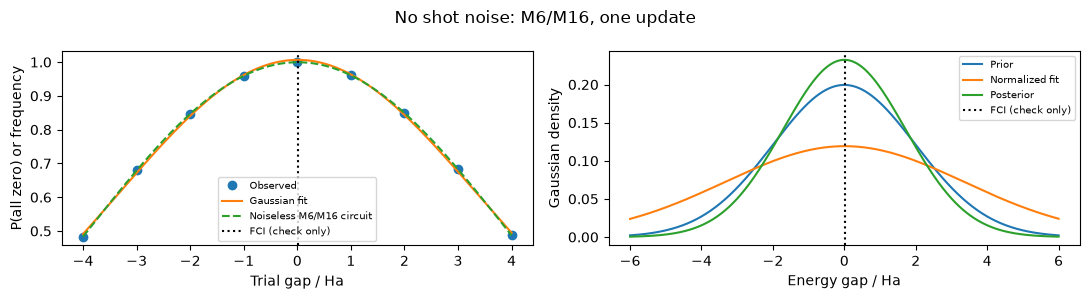

fit center / Ha | posterior mean / Ha | Gaussian SD / Ha | residual RMSE
0.00967351 | 0.00254478 | 1.7169 | 0.0062997
Posterior mean - FCI / Ha: -0.013360182637934606
Saved: outputs/exercise6/no_shot_noise.json


In [4]:
observed_exact = probability("both", L, TRIAL_GAPS)
fit_exact = fit_gaussian_signal(TRIAL_GAPS, observed_exact, PRIOR_MU, PRIOR_VARIANCE)
v_exact = 1 / (1 / PRIOR_VARIANCE + 1 / fit_exact["fit_variance"])
mu_exact = v_exact * (
    PRIOR_MU / PRIOR_VARIANCE + fit_exact["fit_mu"] / fit_exact["fit_variance"]
)
show_result(
    observed_exact, fit_exact, mu_exact, v_exact, "No shot noise: M6/M16, one update"
)
save_result("no_shot_noise", observed_exact, fit_exact, mu_exact, v_exact)
# シミュレーション確率が実際の9 qubit回路と一致することを照合。
for eps, p in zip(TRIAL_GAPS, observed_exact):
    actual = (
        abs(Statevector.from_instruction(experiment_circuit(L, float(eps))).data[0])
        ** 2
    )
    np.testing.assert_allclose(actual, p, atol=1e-10)

## 3．shot noiseありシミュレーション

同じM6/M16回路の確率から、各候補の全0回数を二項乱数で生成します。
このセルも初期事前から1回だけ更新し、第2節の事後を引き継ぎません。乱数seedは42に固定します。
実機のゲートノイズ・読出し誤りは加えていません。


trial gap / Ha | all-zero count / shots
-4.0 | 483/1024
-3.0 | 721/1024
-2.0 | 872/1024
-1.0 | 983/1024
+0.0 | 1024/1024
+1.0 | 997/1024
+2.0 | 874/1024
+3.0 | 721/1024
+4.0 | 504/1024


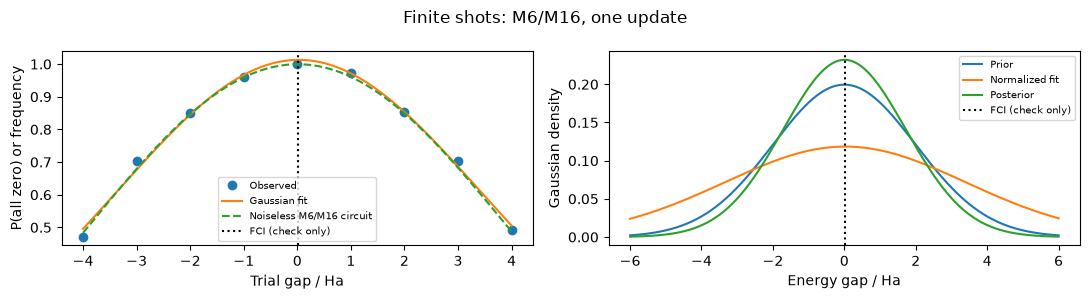

fit center / Ha | posterior mean / Ha | Gaussian SD / Ha | residual RMSE
0.02721753 | 0.00709469 | 1.71969 | 0.015258
Posterior mean - FCI / Ha: -0.008810265665101914
Saved: outputs/exercise6/simulated_counts.json


In [5]:
rng = np.random.default_rng(42)
probabilities_shots = probability("both", L, TRIAL_GAPS)
counts_shots = rng.binomial(SHOTS, probabilities_shots)
observed_shots = counts_shots / SHOTS
print("trial gap / Ha | all-zero count / shots")
for eps, count in zip(TRIAL_GAPS, counts_shots):
    print(f"{eps:+.1f} | {count}/{SHOTS}")
fit_shots = fit_gaussian_signal(TRIAL_GAPS, observed_shots, PRIOR_MU, PRIOR_VARIANCE)
v_shots = 1 / (1 / PRIOR_VARIANCE + 1 / fit_shots["fit_variance"])
mu_shots = v_shots * (
    PRIOR_MU / PRIOR_VARIANCE + fit_shots["fit_mu"] / fit_shots["fit_variance"]
)
show_result(
    observed_shots, fit_shots, mu_shots, v_shots, "Finite shots: M6/M16, one update"
)
save_result(
    "simulated_counts", observed_shots, fit_shots, mu_shots, v_shots, counts_shots
)

## 3a．FakeKawasakiでゲートノイズ・読出し誤りを加える（任意）

次のインストール行を必要に応じて有効にし、カーネルを再起動してから
`USE_FAKE_KAWASAKI=True` で実行します。APIキー・CRN・IBM接続は不要です。
**このスイッチがTrueの間は、後のIBM接続と実機送信もスキップします。**

06と同じM6/M16・L=4・9点を、`FakeKawasaki` の配置・ネイティブゲートへ変換し、
`AerSimulator.from_backend()` のゲート／読出しノイズ付き密度行列シミュレーションで測ります。
Aerが未導入なら停止し、ノイズなしシミュレータへ代替しません。未使用qubitはAerが除外します。
処理時間はPCや配置に依存します。乱数seedは42、各点のshots数はSHOTSです。

**保存スナップショットと現在の実機は異なります。** Runtime 0.43系列の同梱FakeKawasakiは
127 qubit・ECRゲートの過去の装置情報です。今回の実機記録はCZゲートで、物理qubit 155までを使っています。
したがって、このモードは現在のKawasakiの較正や07の実測をそのまま再現するものではありません。
スナップショット日時・ハッシュ・バージョン・配置・全ビットcountsを結果に保存します。`refresh()` は呼びません。

この節はノイズによる信号の変化を確認するための比較です。平坦なデータへGaussian更新を強制せず、
絶対頻度と点ごとの95% Wilson区間を示します。0回の点にも上限を表示します。
出力先は `outputs/exercise6/fake_kawasaki_measurements.json` で、実機の記録とは別です。

参考：[FakeKawasaki v0.43](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/0.43/fake-provider-fake-kawasaki)、
[Fake Providerとスナップショットの注意点](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/0.43/fake-provider)。


In [6]:
# FakeKawasakiを初めて使う場合は、この行を有効にして実行し、カーネルを再起動してください。
# %pip install "qiskit-ibm-runtime>=0.43,<0.44" "qiskit-aer>=0.17,<0.18"
USE_FAKE_KAWASAKI = True  # True: ローカルのノイズ付き模擬Kawasakiを使う


In [7]:
def fake_kawasaki_scan(shots, seed=42):
    """Local Aer noise simulation; never connects to an IBM account or QPU."""
    if not isinstance(shots, int) or isinstance(shots, bool) or shots < 1:
        raise ValueError("shotsは正の整数を指定してください")
    try:
        import qiskit
        import qiskit_aer
        import qiskit_ibm_runtime
        from qiskit_aer import AerSimulator
        from qiskit_ibm_runtime.fake_provider import FakeKawasaki
    except ImportError as exc:
        raise ImportError(
            '先に %pip install "qiskit-ibm-runtime>=0.43,<0.44" "qiskit-aer>=0.17,<0.18" '
            "を実行してカーネルを再起動してください"
        ) from exc

    fake_backend = FakeKawasaki()
    simulator = AerSimulator.from_backend(
        fake_backend,
        method="density_matrix",
        enable_truncation=True,
        max_parallel_experiments=1,
        max_parallel_threads=4,
    )
    if (
        simulator.options.noise_model is None
        or simulator.options.noise_model.is_ideal()
    ):
        raise RuntimeError("FakeKawasakiのノイズモデルが読み込まれていません")
    logical = []
    for gap in TRIAL_GAPS:
        circuit = experiment_circuit(L, float(gap))
        circuit.measure_all()
        logical.append(circuit)
    # This uses the fake device target; execution below remains entirely local.
    isa = transpile(
        logical,
        backend=fake_backend,
        optimization_level=1,
        seed_transpiler=7,
        num_processes=1,
    )
    reports = [
        dict(
            depth=circuit.depth(),
            two_qubit_gates=sum(
                item.operation.num_qubits == 2 for item in circuit.data
            ),
            operations=dict(circuit.count_ops()),
            initial_layout=circuit.layout.initial_index_layout(filter_ancillas=True),
            final_layout=circuit.layout.final_index_layout(filter_ancillas=True),
        )
        for circuit in isa
    ]
    print(
        f"LOCAL FakeKawasaki: {len(isa)} circuits × {shots} shots; "
        f"first depth={reports[0]['depth']}, 2-qubit gates={reports[0]['two_qubit_gates']}",
        flush=True,
    )
    result = simulator.run(isa, shots=shots, seed_simulator=seed).result()
    if not result.success:
        raise RuntimeError(f"Aer simulation failed: {result.status}")
    raw = [dict(result.get_counts(i)) for i in range(len(isa))]
    if any(
        not counts
        or sum(counts.values()) <= 0
        or any(len(bits) != 9 or set(bits) - set("01") for bits in counts)
        for counts in raw
    ):
        raise ValueError("9ビットのcountsまたは実shots数が不正です")
    actual_shots = [sum(counts.values()) for counts in raw]
    zero = [counts.get("0" * 9, 0) for counts in raw]
    snapshot_hashes = {
        name: hashlib.sha256(
            (Path(fake_backend.dirname) / name).read_bytes()
        ).hexdigest()
        for name in [fake_backend.conf_filename, fake_backend.props_filename]
    }
    return dict(
        source="fake_kawasaki_noisy_counts",
        backend=fake_backend.name,
        snapshot_num_qubits=fake_backend.num_qubits,
        snapshot_last_update=fake_backend.properties().last_update_date.isoformat(),
        snapshot_sha256=snapshot_hashes,
        versions=dict(
            qiskit=qiskit.__version__,
            qiskit_ibm_runtime=qiskit_ibm_runtime.__version__,
            qiskit_aer=qiskit_aer.__version__,
        ),
        method="density_matrix",
        noise_model="AerSimulator.from_backend(FakeKawasaki())",
        noise_model_is_ideal=False,
        seed_simulator=seed,
        seed_transpiler=7,
        geometry=SELECTED_GEOMETRY,
        prep_m=SELECTED_PREP_M,
        evolution_m=SELECTED_EVOLUTION_M,
        circuit_digest=CIRCUIT_DIGEST,
        L=L,
        time=L * DT,
        trial_gaps=TRIAL_GAPS.tolist(),
        requested_shots=shots,
        actual_shots=actual_shots,
        counts_all_zero=zero,
        counts=raw,
        values=[k / n for k, n in zip(zero, actual_shots)],
        resources=reports,
    )


def plot_fake_kawasaki(record):
    if record["circuit_digest"] != CIRCUIT_DIGEST:
        raise ValueError("保存結果と現在の回路選択が異なります")
    gaps = np.asarray(record["trial_gaps"])
    k, n = np.asarray(record["counts_all_zero"]), np.asarray(record["actual_shots"])
    y = k / n
    z = 1.959963984540054
    denominator = 1 + z * z / n
    center = (y + z * z / (2 * n)) / denominator
    half = z * np.sqrt(y * (1 - y) / n + z * z / (4 * n * n)) / denominator
    low, high = np.maximum(0, center - half), np.minimum(1, center + half)
    dense = np.linspace(gaps[0], gaps[-1], 501)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3))
    for ax in axes:
        ax.errorbar(
            gaps,
            y,
            yerr=np.maximum(0, np.array([y - low, high - y])),
            fmt="o",
            capsize=3,
            label="FakeKawasaki / pointwise 95% CI",
        )
        ax.axhline(1 / 512, color="gray", ls=":", label="Uniform 9-bit reference")
        ax.set(xlabel="Trial gap / Ha", ylabel="P(all zero) or frequency")
    axes[0].plot(
        dense, probability("both", record["L"], dense), "--", label="Noiseless M6/M16"
    )
    axes[0].set_ylim(-0.02, 1.02)
    axes[1].set(
        title="Noisy counts (zoom)", ylim=(0, max(float(high.max()), 1 / 512) * 1.15)
    )
    for ax in axes:
        ax.legend(fontsize=7)
    fig.suptitle("LOCAL noisy simulation — historical FakeKawasaki snapshot")
    plt.tight_layout()
    plt.show()
    plt.close(fig)


LOCAL FakeKawasaki: 9 circuits × 1024 shots; first depth=3730, 2-qubit gates=1908
Saved: outputs/exercise6/fake_kawasaki_measurements.json
Snapshot: 2025-02-26T13:56:01-05:00 qubits: 127
trial gap / Ha | all-zero count / actual shots
-4.0 | 2/1024
-3.0 | 6/1024
-2.0 | 1/1024
-1.0 | 3/1024
+0.0 | 1/1024
+1.0 | 5/1024
+2.0 | 5/1024
+3.0 | 0/1024
+4.0 | 2/1024


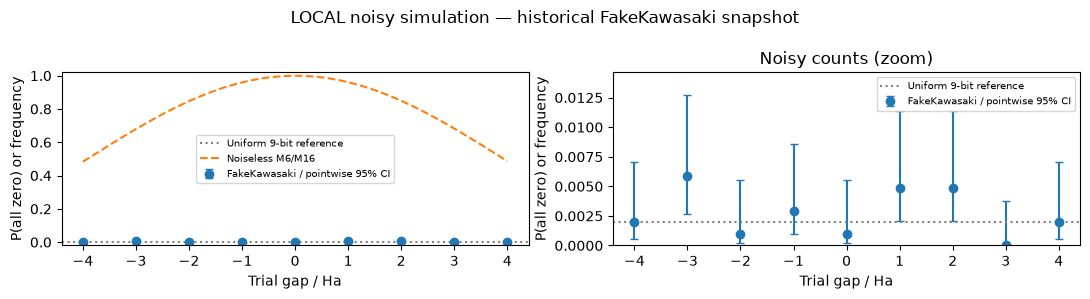

In [8]:
fake_kawasaki_record = None
if USE_FAKE_KAWASAKI:
    fake_kawasaki_record = fake_kawasaki_scan(SHOTS, seed=42)
    fake_path = Path("outputs/exercise6/fake_kawasaki_measurements.json")
    fake_path.parent.mkdir(parents=True, exist_ok=True)
    # Preserve all counts before plotting; never overwrite real IBM job records.
    fake_path.write_text(json.dumps(fake_kawasaki_record, indent=2))
    print("Saved:", fake_path)
    print(
        "Snapshot:",
        fake_kawasaki_record["snapshot_last_update"],
        "qubits:",
        fake_kawasaki_record["snapshot_num_qubits"],
    )
    print("trial gap / Ha | all-zero count / actual shots")
    for gap, k, n in zip(
        TRIAL_GAPS,
        fake_kawasaki_record["counts_all_zero"],
        fake_kawasaki_record["actual_shots"],
    ):
        print(f"{gap:+.1f} | {k}/{n}")
    plot_fake_kawasaki(fake_kawasaki_record)
else:
    print("FakeKawasakiをスキップ。使う場合はUSE_FAKE_KAWASAKI=Trueにしてください。")


## IBM Quantum接続準備（実機を使う方のみ）

シミュレータのみで演習する方は、そのままスキップできます。
実機を使う方は次セルの `USE_IBM = True` に変更して実行してください。
パッケージのインストール後、本人のAPIキーと今回使うインスタンスのCRNを入力し、
表示されたバックエンド名から利用する実機を選びます。**ここではジョブを送信しません。**

APIキー作成・CRN取得の手順：接続確認ガイド（[https://github.com/QS-laboratory/IBM_handson/blob/main/docs/02_colab_connection.md](https://github.com/QS-laboratory/IBM_handson/blob/main/docs/02_colab_connection.md)）。
実習用インスタンスは **us-east** の **FTQC-HandsOn-20261109** です。
ご所属の利用枠を使う方は、今回の演習に利用できるインスタンスを指定してください。
APIキーは非表示入力し、コード本文・出力・GitHubへ貼り付けないでください。
事前確認用キーを削除した方は、新しいキーを作成してください。

接続情報は次の実機プレビューへ引き継ぎます。`RUN_HARDWARE = False` のまま、L=4の回路費用を確認してください。
費用確認後、送信する場合だけ `RUN_HARDWARE = True` に変更します。新規ランタイムではこの接続準備を再実行します。


In [6]:
USE_IBM = True  # 実機を使う方のみ True に変更
IBM_SERVICE = None
IBM_INSTANCE = ""
IBM_BACKEND_NAME = ""

if USE_IBM and not globals().get("USE_FAKE_KAWASAKI", False):
    import subprocess
    import sys
    from getpass import getpass

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "qiskit==2.4.1",
            "qiskit-ibm-runtime>=0.43,<0.44",
        ]
    )
    from qiskit_ibm_runtime import QiskitRuntimeService

    IBM_INSTANCE = input("今回使うインスタンスのCRN：").strip()
    if not IBM_INSTANCE.startswith("crn:"):
        raise ValueError("インスタンスのCRN（crn:で始まる文字列）を入力してください")
    _api_key = getpass("本人のAPIキー（非表示）：").strip()
    try:
        IBM_SERVICE = QiskitRuntimeService(
            channel="ibm_quantum_platform",
            token=_api_key,
            instance=IBM_INSTANCE,
        )
    finally:
        del _api_key

    _backend_names = sorted(b.name for b in IBM_SERVICE.backends())
    print("利用可能なバックエンド：", ", ".join(_backend_names))
    if not _backend_names:
        raise RuntimeError("利用可能な実機がありません。主催者へお知らせください")
    IBM_BACKEND_NAME = input("一覧から今回使うバックエンド名を入力：").strip()
    if IBM_BACKEND_NAME not in _backend_names:
        raise ValueError(
            "一覧にあるバックエンド名を入力し、このセルを再実行してください"
        )
    print("接続確認完了：", IBM_BACKEND_NAME, "（ジョブは送信していません）")
else:
    print("IBM接続準備をスキップしました。シミュレータで演習できます。")


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
qiskit_runtime_service._discover_account:WARNING:2026-11-09 15:09:28,659: Loading account with the given token. A saved account will not be used.


利用可能なバックエンド： ibm_kawasaki
接続確認完了： ibm_kawasaki （ジョブは送信していません）


## 4．実機：まず同じL=4の回路費用を確認する

上の接続準備セルを`USE_IBM=True`にして実行すると、CRN・本人のAPIキー・バックエンドを入力できます。
ここは05から移した実機セットアップです。認証情報はNotebookへ書き込みません。
次セルはL=4でトランスパイルし、深さ・2 qubitゲート数を表示します。ジョブは送信しません。

この直列回路は接続制約を考える前でCX換算1380個（516+216×4）あり、実機上のゲート数は配置・最適化で変わります。
同じ9点でも深い回路のノイズで信号が潰れ、Gaussianフィットが不適切になる可能性があります。


In [7]:
backend = None
preview = None
if IBM_SERVICE is not None:
    backend = IBM_SERVICE.backend(IBM_BACKEND_NAME)
    preview = hardware_preview(backend, L=4)
    print(
        "Circuits:", 9, "shots per circuit:", SHOTS, "total requested shots:", 9 * SHOTS
    )
else:
    print("IBM接続なし：プレビューをスキップ。上のシミュレーションは実行できます。")

NameError: name 'hardware_preview' is not defined

### 実機の9点を測り、初期事前から1回だけ更新する

プレビューの費用を確認したら、次セルの`RUN_HARDWARE=True`で送信を有効にします。
これは送信操作のスイッチで、測定の科学的パラメータはSHOTS以外すべて固定です。
9回路を1ジョブで実行し、全0回数を全shotsで割ります。3節の事後は引き継ぎません。

ジョブIDとcountsは`outputs/exercise6/ibm_jobs/`へ保存します。同条件で再実行すると保存結果／ジョブを再利用します。
SHOTSが変われば別条件となり、新しいジョブになります。Colabでは切断前に記録をDrive等へ保存してください。
測定記録をフィット前に保存し、フィット失敗時も実機countsを残します。


Submitting 9 circuits; 1024 shots each; L= 4
Saved job ID: dbol5i8ou4as73cs9ajg in outputs/exercise6/ibm_jobs/429d8dd65bf95ce095abfd8cfe535955420a107ae3510e020b3805fbc235ee9f.json
trial gap / Ha | all-zero count / actual shots
-4.0 | 2/1024
-3.0 | 1/1024
-2.0 | 0/1024
-1.0 | 4/1024
+0.0 | 1/1024
+1.0 | 1/1024
+2.0 | 1/1024
+3.0 | 1/1024
+4.0 | 2/1024


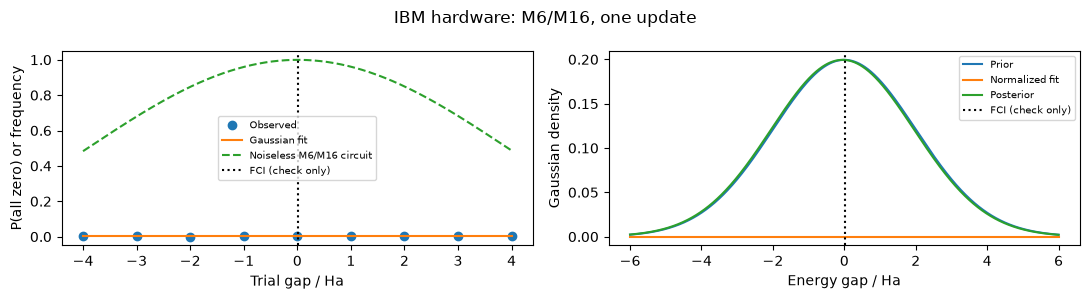

fit center / Ha | posterior mean / Ha | Gaussian SD / Ha | residual RMSE
-1025.90389177 | -0.04842866 | 1.99995 | 0.0010399
Posterior mean - FCI / Ha: -0.0643336141454266
Saved: outputs/exercise6/ibm_update.json


In [ ]:
RUN_HARDWARE = True  # 費用確認後、実機へ送信する場合だけTrue
if RUN_HARDWARE and not globals().get("USE_FAKE_KAWASAKI", False):
    if backend is None or preview is None or preview["L"] != 4:
        raise RuntimeError("先にIBM接続とL=4のプレビューを実行してください")
    ibm_meter = Measurement(
        "ibm",
        SHOTS,
        42,
        service=IBM_SERVICE,
        backend=backend,
        run_hardware=True,
        max_hardware_L=4,
        directory="outputs/exercise6/ibm_jobs",
    )
    observed_ibm = ibm_meter.measure("both", 4, TRIAL_GAPS, "one_update")
    ibm_meter.save("outputs/exercise6/ibm_measurements.json")
    raw_counts = ibm_meter.records[-1]["counts"]
    print("trial gap / Ha | all-zero count / actual shots")
    for eps, counts in zip(TRIAL_GAPS, raw_counts):
        print(f"{eps:+.1f} | {counts.get('0' * 9, 0)}/{sum(counts.values())}")
    fit_ibm = fit_gaussian_signal(TRIAL_GAPS, observed_ibm, PRIOR_MU, PRIOR_VARIANCE)
    v_ibm = 1 / (1 / PRIOR_VARIANCE + 1 / fit_ibm["fit_variance"])
    mu_ibm = v_ibm * (
        PRIOR_MU / PRIOR_VARIANCE + fit_ibm["fit_mu"] / fit_ibm["fit_variance"]
    )
    show_result(
        observed_ibm, fit_ibm, mu_ibm, v_ibm, "IBM hardware: M6/M16, one update"
    )
    # 実際のshotsと全ビットcountsは、上のibm_measurements.jsonに保存済み。
    path = Path("outputs/exercise6/ibm_update.json")
    path.write_text(
        json.dumps(
            dict(
                prior_mu=PRIOR_MU,
                prior_variance=PRIOR_VARIANCE,
                fit=fit_ibm,
                posterior_mu=float(mu_ibm),
                posterior_variance=float(v_ibm),
            ),
            indent=2,
        )
    )
    print("Saved:", path)
elif globals().get("USE_FAKE_KAWASAKI", False):
    print("FakeKawasakiモード：実機送信をスキップしました。")
else:
    print("実機送信なし。費用確認後、このセルだけRUN_HARDWARE=Trueにして実行します。")

## 5．比較の読み方と解答

1. shot noiseなしのフィット中心がFCIと一致しないのはなぜか。  
   **解答：** M6/M16の回路近似と余弦信号のGaussian近似があります。また事後平均には初期事前と1回だけの更新も影響します。
2. SHOTSを増やせば、実機結果はshot noiseなしの結果へ必ず近づくか。  
   **解答：** ゲートノイズなしの有限shotsシミュレータでは頻度のばらつきが減ります。実機のゲートノイズ・読出し誤り・ドリフトによる偏りはshots増加だけでは消えません。
3. 3通りの結果は3回の連続更新か。  
   **解答：** いいえ。同じ初期事前$N(0,4)$から独立に1回更新した比較です。次の事前への反復は05で扱います。
4. 実機のGaussianフィットが数値的に終われば、ギャップを推定できたといえるか。  
   **解答：** いえません。測定とフィットの図、残差、shot noiseなしの同じ近似回路の信号を比較します。信号が潰れた場合、単に出力された中心や小さいSDを根拠に成功としません。
5. SHOTS=1024で必要な実機shots数はいくつか。  
   **解答：** 9×1024=9216 shotsです。第2節ではshotsを使わず、第3節は模擬測定なので実機の利用量に含みません。

実機未接続でも第2・3節は実行できます。本Notebookのローカル検証では実機へ送信しません。
出所・固定データ・Gaussian更新の数値規約は05と共通です。
